1DECISION TREE

Tasks:      
1. Data Preparation:        
Load the dataset into your preferred data analysis environment (e.g., Python with libraries like Pandas and NumPy).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_excel("heart_disease.xlsx",sheet_name='Heart_disease')

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


In [4]:
df.shape

(908, 13)

2. Exploratory Data Analysis (EDA):     
Perform exploratory data analysis to understand the structure of the dataset.       
Check for missing values, outliers, and inconsistencies in the data.        
Visualize the distribution of features, including histograms, box plots, and correlation matrices.


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    str    
 2   cp        908 non-null    str    
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    object 
 6   restecg   908 non-null    str    
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    str    
 11  thal      908 non-null    str    
 12  num       908 non-null    int64  
dtypes: float64(1), int64(5), object(2), str(5)
memory usage: 132.4+ KB


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    str    
 2   cp        908 non-null    str    
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    object 
 6   restecg   908 non-null    str    
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    str    
 11  thal      908 non-null    str    
 12  num       908 non-null    int64  
dtypes: float64(1), int64(5), object(2), str(5)
memory usage: 132.4+ KB


In [7]:
df['exang'] = df['exang'].astype(str).replace({
    'FALSE': 'False', 
    'TURE': 'True'
})

print(df['exang'].unique())

<ArrowStringArray>
['False', 'True']
Length: 2, dtype: str


In [8]:
df['fbs'] = df['fbs'].astype(str).replace({
    'FALSE': 'False', 
    'TRUE': 'True',
    'TURE': 'True'
})

print(df['fbs'].unique())

<ArrowStringArray>
['True', 'False']
Length: 2, dtype: str


In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.isnull().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

In [12]:
df['oldpeak']=df['oldpeak'].fillna(df['oldpeak'].median())

In [13]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
thal        0
num         0
dtype: int64

In [14]:
target=df['num']
features=df.drop(columns=['num'])

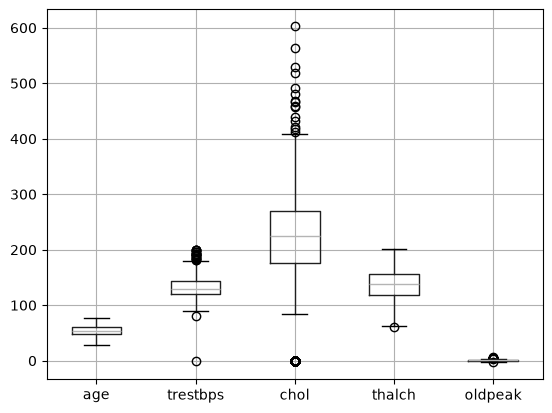

In [15]:
features.boxplot()
plt.show()

In [16]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

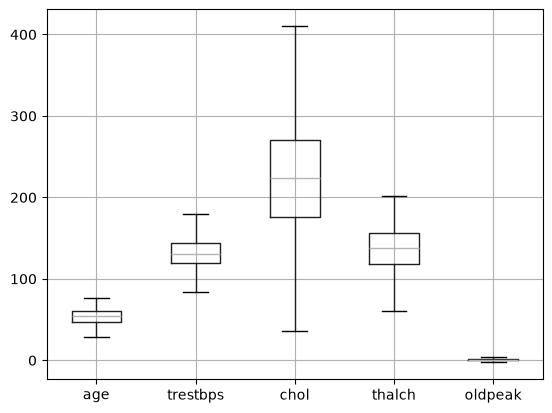

In [17]:
features.boxplot()
plt.show()

<Figure size 1000x800 with 0 Axes>

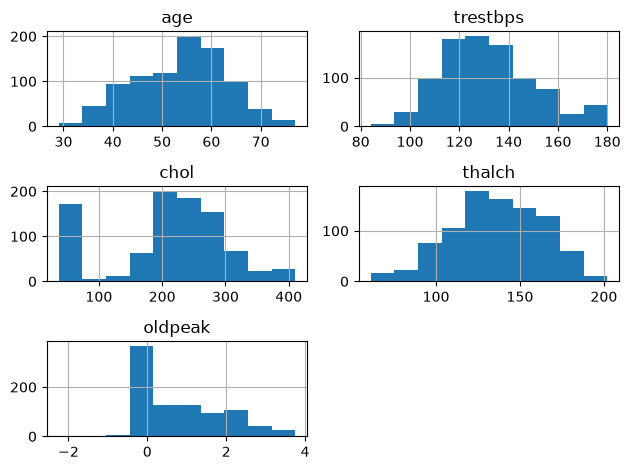

In [18]:
plt.figure(figsize=(10,8))
features.hist()
plt.tight_layout()
plt.show()

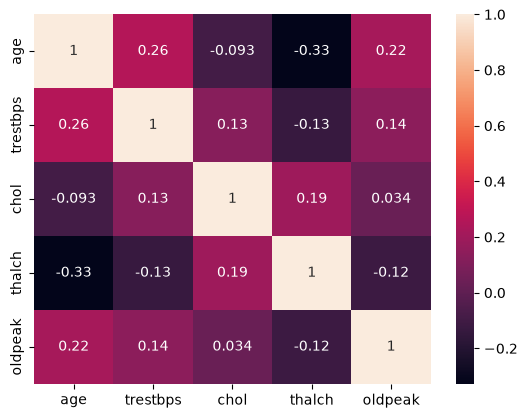

In [19]:
num_cols=features.select_dtypes(include=['int64', 'float64']).columns
cor=features[num_cols].corr()
sns.heatmap(cor,annot=True)
plt.show()

3. Feature Engineering:     
If necessary, perform feature engineering techniques such as encoding categorical variables, scaling numerical features, or handling missing values.


In [20]:
cat_cols=features.select_dtypes(include=(['object','bool'])).columns.to_list()

C:\Users\pprem\AppData\Local\Temp\ipykernel_18960\1528421882.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=features.select_dtypes(include=(['object','bool'])).columns.to_list()


In [21]:
cat_cols

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

In [22]:
#onehotencoding
features=pd.get_dummies(features,columns=cat_cols,drop_first=True)

In [23]:
features

,age,trestbps,chol,thalch,oldpeak,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,fbs_True,restecg_normal,restecg_st-t abnormality,exang_True,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,145.0,233.00,150.0,2.3,True,False,False,True,True,False,False,False,False,False,False,False
1,41,135.0,203.00,132.0,0.0,True,True,False,False,False,True,False,False,True,False,False,False
2,57,140.0,192.00,148.0,0.4,True,False,False,False,False,True,False,False,True,False,False,False
3,52,118.0,186.00,190.0,0.0,True,False,False,True,False,False,False,False,True,False,False,False
4,57,110.0,201.00,126.0,1.5,True,False,False,False,False,True,False,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,125.0,36.25,120.0,1.5,True,False,False,False,False,True,False,False,False,True,True,False
904,62,166.0,170.00,120.0,3.0,True,False,False,False,False,False,True,True,True,False,False,True
905,56,170.0,36.25,123.0,2.5,True,False,True,False,False,False,False,True,False,False,False,True
906,56,144.0,208.00,105.0,0.5,True,False,True,False,True,False,True,True,False,False,False,True


In [24]:
num_cols=features.select_dtypes(include=['int64', 'float64']).columns.to_list()

In [25]:
num_cols

['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
std_sca=StandardScaler()

In [28]:
features[num_cols]=std_sca.fit_transform(features[num_cols])

In [29]:
features

,age,trestbps,chol,thalch,oldpeak,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,fbs_True,restecg_normal,restecg_st-t abnormality,exang_True,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,1.006097,0.608289,0.265386,0.523305,1.409890,True,False,False,True,True,False,False,False,False,False,False,False
1,-1.396447,0.089952,-0.043590,-0.148458,-0.835450,True,True,False,False,False,True,False,False,True,False,False,False
2,0.350858,0.349120,-0.156881,0.448665,-0.444956,True,False,False,False,False,True,False,False,True,False,False,False
3,-0.195175,-0.791221,-0.218677,2.016110,-0.835450,True,False,False,True,False,False,False,False,True,False,False,False
4,0.350858,-1.205891,-0.064188,-0.372378,0.628902,True,False,False,False,False,True,False,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,-0.085969,-0.428385,-1.760984,-0.596299,0.628902,True,False,False,False,False,True,False,False,False,True,True,False
904,0.896890,1.696797,-0.383464,-0.596299,2.093254,True,False,False,False,False,False,True,True,True,False,False,True
905,0.241651,1.904132,-1.760984,-0.484339,1.605137,True,False,True,False,False,False,False,True,False,False,False,True
906,0.241651,0.556455,0.007906,-1.156101,-0.347333,True,False,True,False,True,False,True,True,False,False,False,True


4. Decision Tree Classification:        
Split the dataset into training and testing sets (e.g., using an 80-20 split).      
Implement a Decision Tree Classification model using a library like scikit-learn.       
Train the model on the training set and evaluate its performance on the testing set using appropriate evaluation metrics (e.g., accuracy, precision, recall, F1-score, ROC-AUC).


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [31]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.2,random_state=42)

In [32]:
dt_model=DecisionTreeClassifier()
dt_model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [33]:
y_pred=dt_model.predict(x_test)

In [34]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.79      0.69      0.73        89
           1       0.31      0.34      0.32        47
           2       0.18      0.20      0.19        20
           3       0.08      0.12      0.10        17
           4       0.17      0.11      0.13         9

    accuracy                           0.46       182
   macro avg       0.31      0.29      0.30       182
weighted avg       0.50      0.46      0.48       182



5. Hyperparameter Tuning:       
Perform hyperparameter tuning to optimize the Decision Tree model. Experiment with different hyperparameters such as maximum depth, minimum samples split, and criterion.


In [36]:
from sklearn.model_selection import GridSearchCV

In [35]:
param_grid={
    'criterion':['gini','entropy'],
    'max_depth':[3,5,7],
    'min_samples_split':[2,5],
    'min_samples_leaf':[1,5]
}

In [37]:
grid_search=GridSearchCV(estimator=DecisionTreeClassifier(),param_grid=param_grid,cv=5,scoring='accuracy')

In [38]:
grid_search.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 5], 'min_samples_split': [2, 5]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [39]:
grid_search.best_estimator_,grid_search.best_params_

(DecisionTreeClassifier(max_depth=3),
 {'criterion': 'gini',
  'max_depth': 3,
  'min_samples_leaf': 1,
  'min_samples_split': 2})

6. Model Evaluation and Analysis:       
Analyse the performance of the Decision Tree model using the evaluation metrics obtained.       
Visualize the decision tree structure to understand the rules learned by the model and identify important features


In [40]:
best_dt_model=grid_search.best_estimator_

In [42]:
y_pred=best_dt_model.predict(x_test)

In [45]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.82      0.78        89
           1       0.40      0.43      0.41        47
           2       0.11      0.05      0.07        20
           3       0.08      0.12      0.10        17
           4       0.00      0.00      0.00         9

    accuracy                           0.53       182
   macro avg       0.27      0.28      0.27       182
weighted avg       0.48      0.53      0.50       182



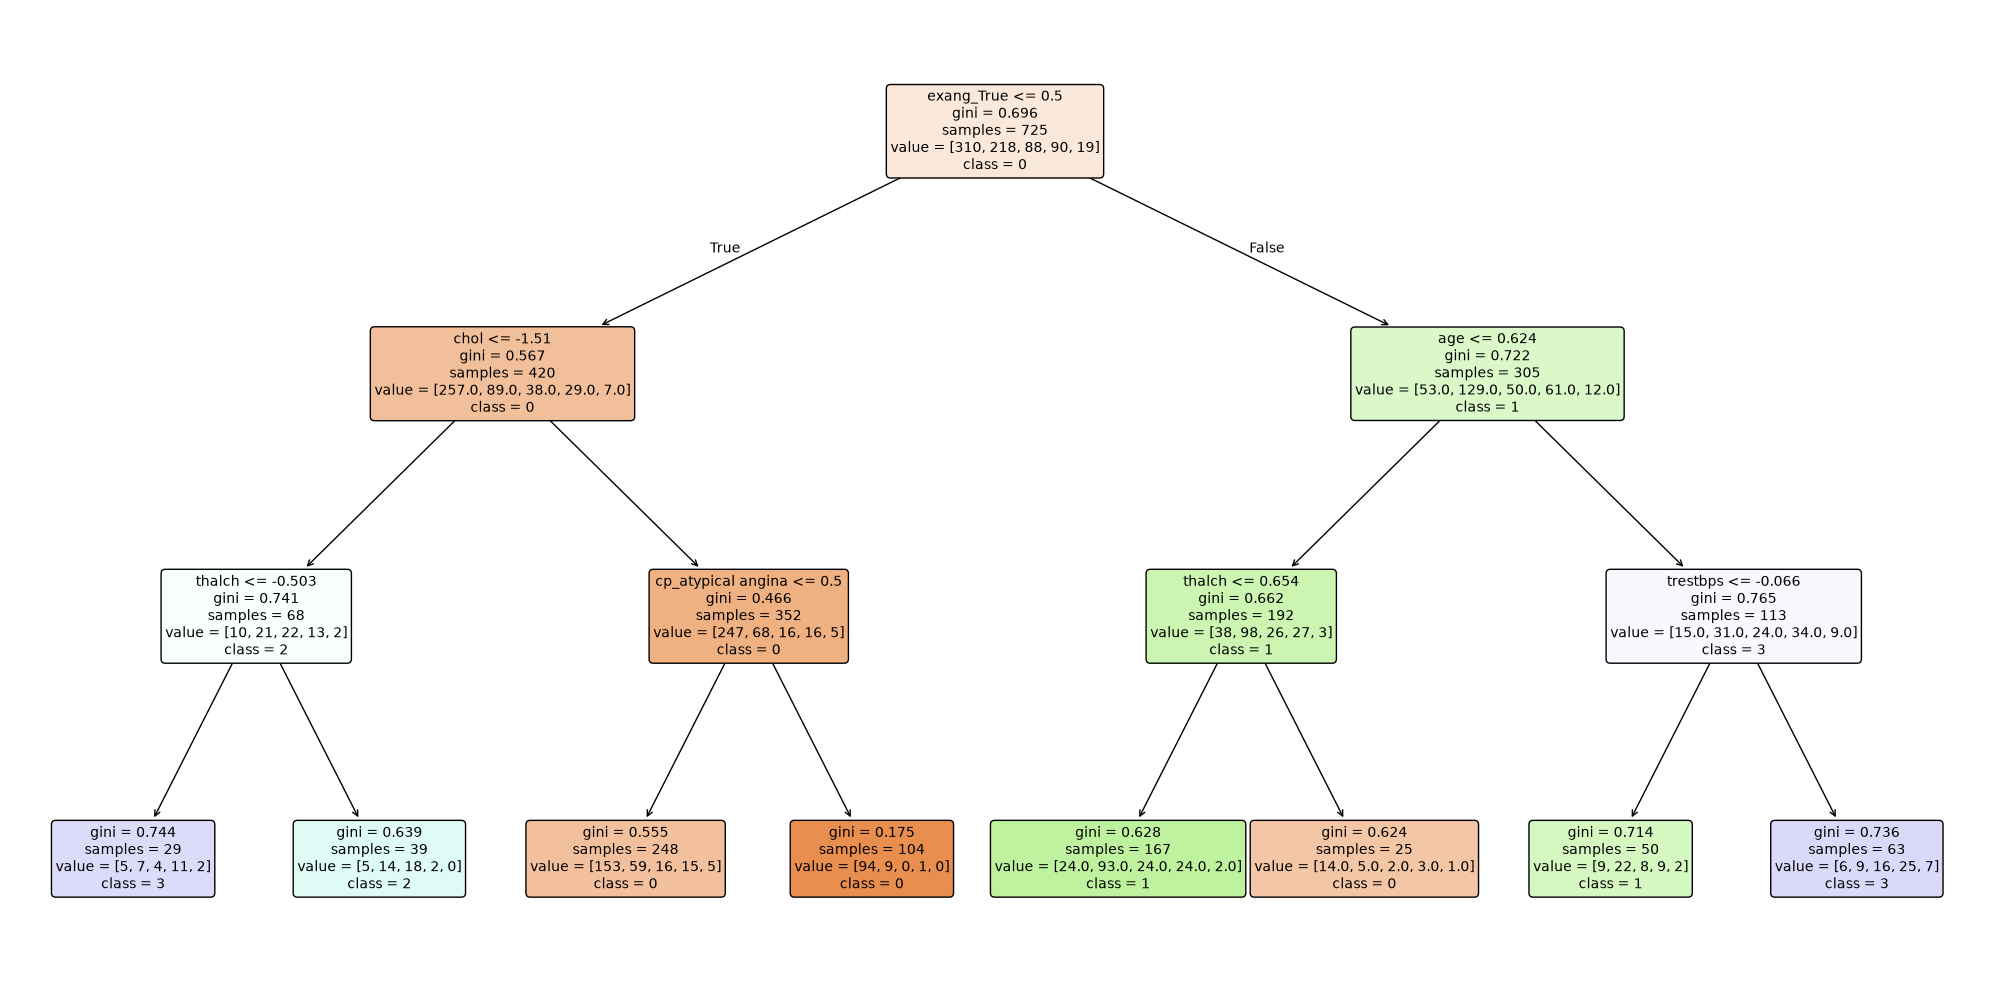

In [60]:
plt.figure(figsize=(20, 10))
plot_tree(
    best_dt_model, 
    feature_names=features.columns.to_list(), 
    class_names=[str(c) for c in best_dt_model.classes_], 
    filled=True, 
    rounded=True, 
    fontsize=10
) 
plt.tight_layout()
plt.show()

Interview Questions:        
1. What are some common hyperparameters of decision tree models, and how do they affect the model's performance?

In [1]:
print("""      

Decision tree hyperparameters, such as maximum depth and minimum sample splits, restrict how large 
and complex the tree can grow. Tuning these settings controls the bias-variance tradeoff and prevents
the model from perfectly memorizing and overfitting the training data.

""")

      

Decision tree hyperparameters, such as maximum depth and minimum sample splits, restrict how large 
and complex the tree can grow. Tuning these settings controls the bias-variance tradeoff and prevents
the model from perfectly memorizing and overfitting the training data.




2. What is the difference between the Label encoding and One-hot encoding?

In [2]:
print("""      

Label encoding assigns a unique integer to each category, which is best for ordinal data where an 
inherent ranking exists. One-hot encoding creates a separate binary column for every category, which 
is ideal for unordered nominal data to prevent models from assuming false mathematical relationships.

""")

      

Label encoding assigns a unique integer to each category, which is best for ordinal data where an 
inherent ranking exists. One-hot encoding creates a separate binary column for every category, which 
is ideal for unordered nominal data to prevent models from assuming false mathematical relationships.


